In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import cmaps
#import matplotlib.colors as colors
import cartopy.crs as ccrs
import matplotlib as mpl
import numpy as np
import xarray as xr

In [2]:
# define simple plotter
def plot(da, ax, transform=ccrs.PlateCarree(), projection=ccrs.PlateCarree(), vmin=None, vmax=None, norm=None, borders=True,xlocs=range(-180,180,10), ylocs=range(-90,90,10), extent=None, figsize=(15,10), title='', cmap='rainbow'):
    """plot a domain using the right projections and transformations with cartopy"""
    #%matplotlib inline
    import cartopy.feature as cf

    ax.projection=projection
    if extent:
        ax.set_extent(extent, crs=projection)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray',
                      xlocs=xlocs, ylocs=ylocs, x_inline=False, y_inline=False)
    gl.xlines = True
    gl.ylines = True
    gl.xlabel_style = {'size': 15}
    gl.ylabel_style = {'size': 15}
    gl.top_labels = False
    sbl = da.plot(ax=ax, norm=norm, cmap=cmap, transform=transform, vmin=vmin, vmax=vmax, add_colorbar=False)
    ax.coastlines(resolution='50m', color='black', linewidth=1)
    if borders: ax.add_feature(cf.BORDERS)
    if borders: ax.add_feature(cf.LAKES.with_scale('50m'), facecolor='white',
        edgecolor='black', zorder=0)
    ax.set_title(title)
    return sbl

In [3]:
# define data paths
rdata = './data_in/model_data/REMO_static/'
figpath = './figures/'

In [4]:
# create variable info class for model
class modelclass:
    def __init__(self, runame, filename, varname):
        self.runame = runame # name of the run
        self.filename = filename
        self.varname = varname
        self.plotvar = []

In [5]:
# define the runs to be plotted
modelruns =[] # init

modelruns.append(modelclass("REMO-TEB GLCC","urban_fractions_EUR-11.nc","GLCC"))
modelruns.append(modelclass("REMO-TEB ECOCLIMAP-SG LZCs","urban_fractions_EUR-11.nc","ECOSG_LCZ"))
modelruns.append(modelclass("REMO-TEB-iMOVE Landmate","urban_fractions_EUR-11.nc","LANDMATE"))
modelruns.append(modelclass("REMO-TEB GLCC","urban_fractions_ALPX-3.nc","GLCC"))
modelruns.append(modelclass("REMO-TEB ECOCLIMAP-SG LZCs","urban_fractions_ALPX-3.nc","ECOSG_LCZ"))
modelruns.append(modelclass("REMO-TEB-iMOVE Landmate","urban_fractions_ALPX-3.nc","LANDMATE"))

In [6]:
# get model data
ii = 0
for obj in modelruns:
    # open data and select variable
    ds = xr.open_dataset(rdata+obj.filename)
    obj.plotvar = ds[obj.varname]
    #obj.plotvar = obj.plotvar.where(obj.plotvar > 0.0,drop=False) # not needed if first index of colormap is white
    if(ii != 0):
        pole = (ds.rotated_latitude_longitude.grid_north_pole_longitude,ds.rotated_latitude_longitude.grid_north_pole_latitude)
    ii = ii + 1

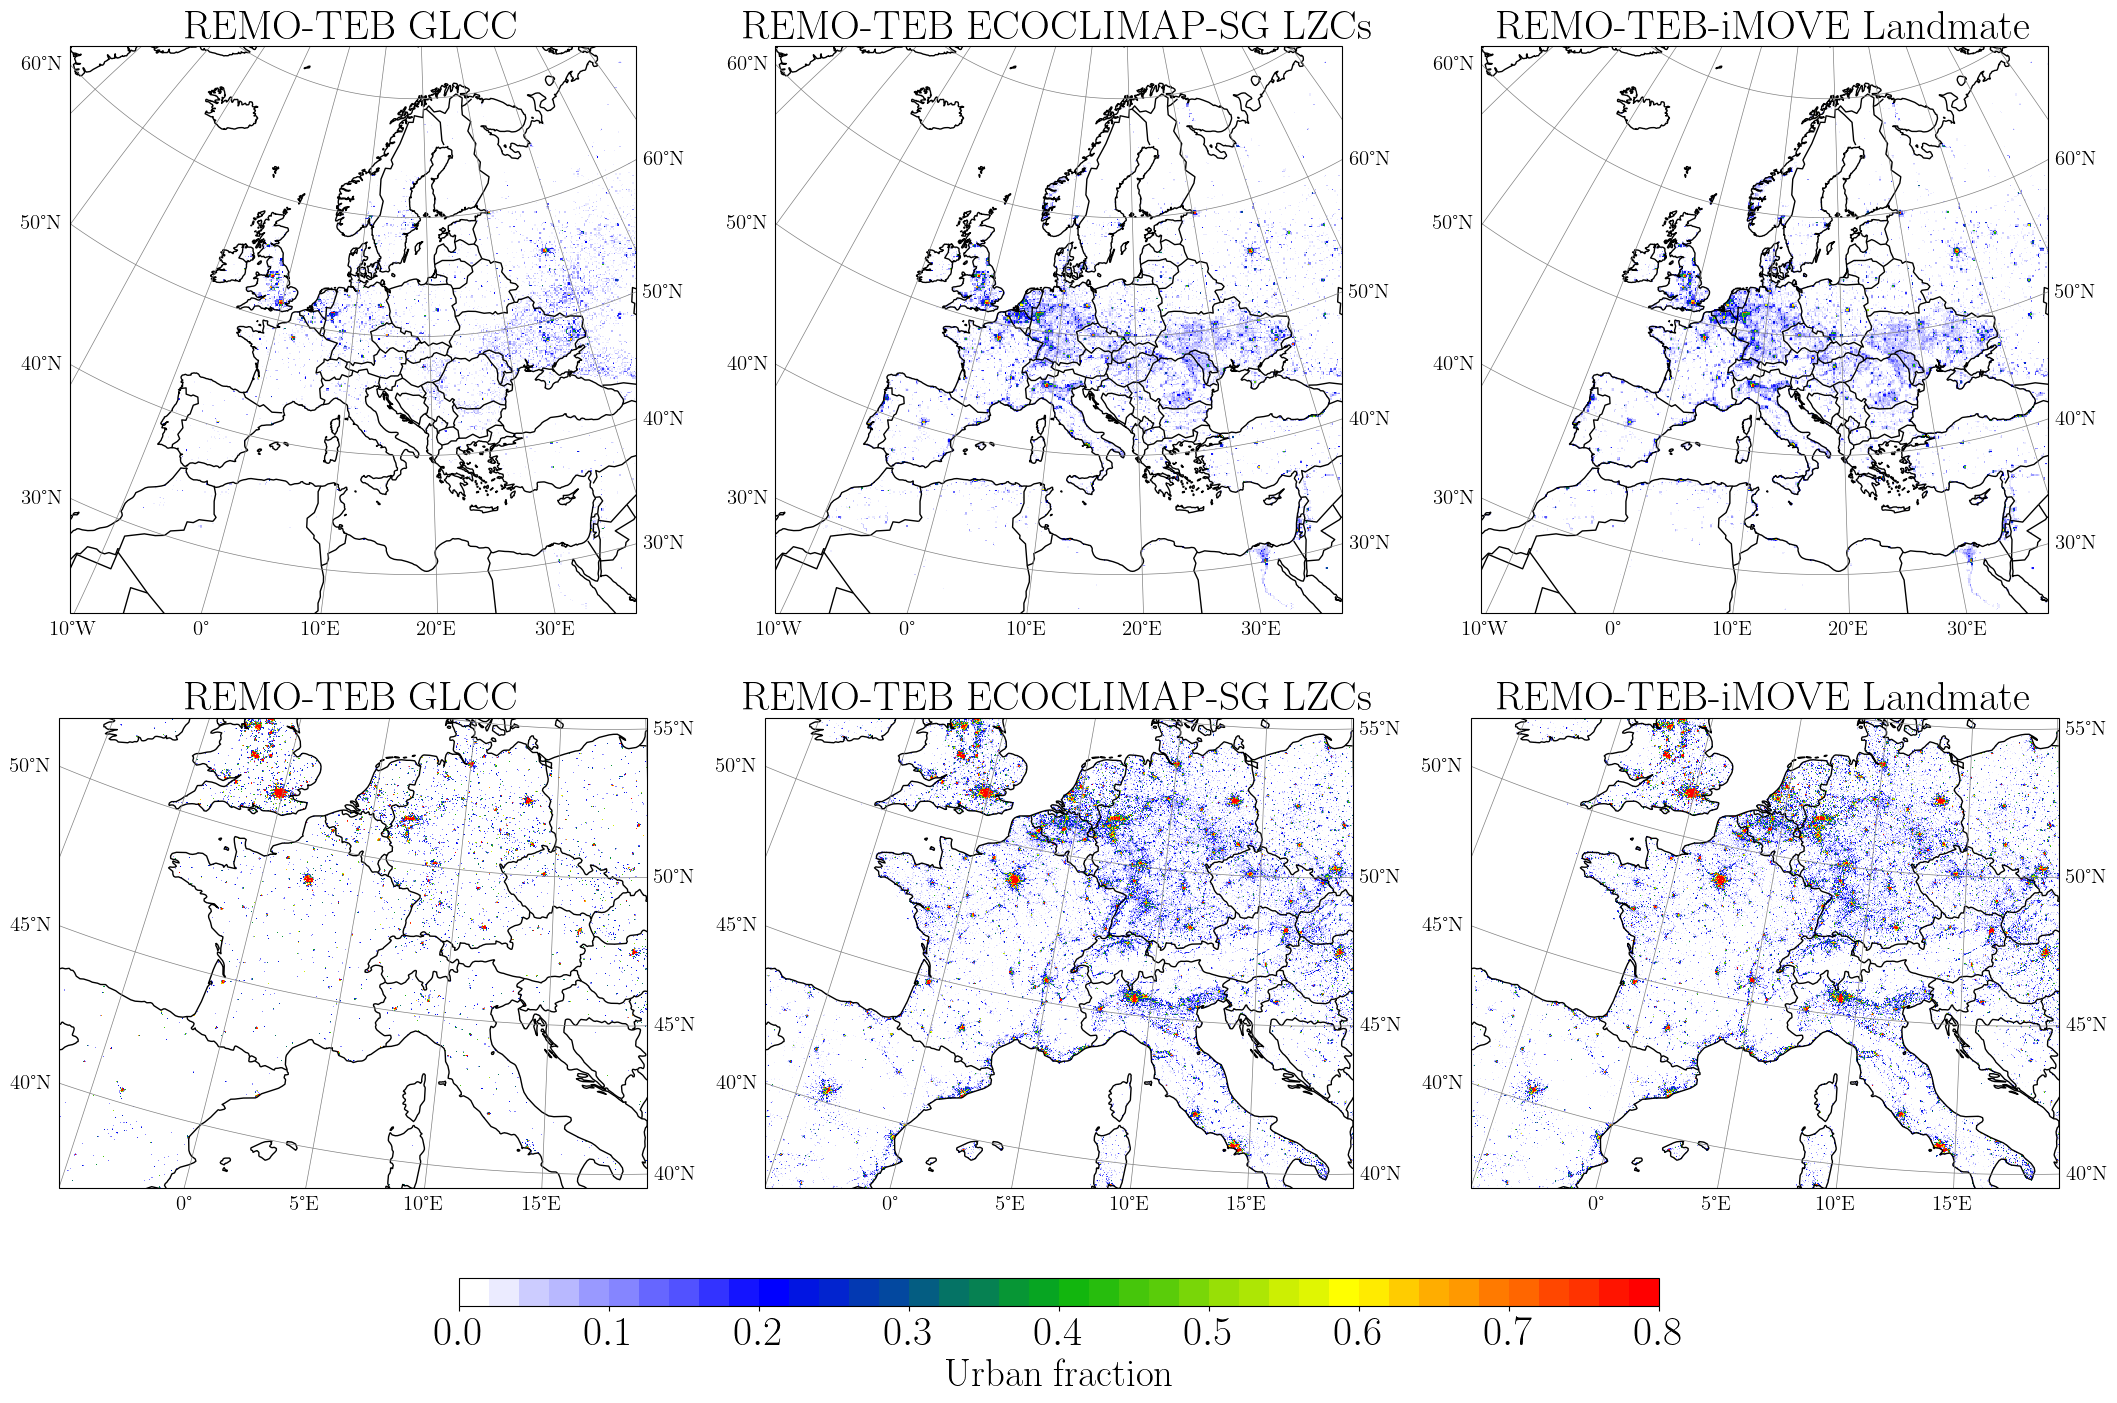

In [7]:
matplotlib.rcParams.update(matplotlib.rcParamsDefault)
# set default plot size larger for convenience
matplotlib.rcParams['figure.figsize'] = (20, 14)
# Bring title text closer to figure
matplotlib.rcParams['axes.titlepad'] = 0
plt.rcParams["figure.subplot.hspace"] = 0.1# the amount of height reserved for white space between subplots
plt.rcParams["figure.subplot.wspace"] = 0.2 # the amount of height reserved for white space between subplots
plt.rcParams["axes.titlesize"] = 30
plt.rcParams['axes.labelsize'] = 30
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = 'serif'
plt.rcParams["xtick.labelsize"] = 30
plt.rcParams["ytick.labelsize"] = 30
plt.rcParams["legend.fontsize"] = 34

# Open subplot
fig, ((ax)) = plt.subplots(nrows=2,ncols=3,subplot_kw={'projection': ccrs.RotatedPole(*pole)})
fig.subplots_adjust(bottom=0.15, top=1.0, left=0, right=1.0)

# set colorbar limits
vmin = 0.
vmax = 0.8

# create new colormap (1st index will be white)
cmap = cmaps.WhBlGrYeRe(np.linspace(0,1,40))
newcmap = ListedColormap(cmap[::1])

# determine colormap and the maximum and minimum values 
norm =mpl.colors.Normalize(vmin, vmax) 

# add plots
ii = 0
jj = 0
for obj in modelruns:
    # do the plots
    if(ii == 0):
        sbl = plot(obj.plotvar, ax[ii,jj], transform = ccrs.RotatedPole(*pole), projection=ccrs.RotatedPole(*pole), norm=norm, title=obj.runame, cmap=newcmap)
    else:
        sbl = plot(obj.plotvar, ax[ii,jj], transform = ccrs.RotatedPole(*pole), projection=ccrs.RotatedPole(*pole), norm=norm, xlocs=range(-180,180,5), ylocs=range(-90,90,5), title=obj.runame, cmap=newcmap)
    # increase counter
    jj = jj + 1
    if(jj > 2):
        # increase counter
        ii = ii + 1
        # set to zero
        jj = 0
        
# Add a colorbar axis at the bottom of the graph
cbar_ax = fig.add_axes([0.2, 0.1, 0.6, 0.02])

# Draw the colorbar
cbar=fig.colorbar(sbl, cax=cbar_ax, norm=norm,cmap=newcmap,orientation='horizontal')
# add label
cbar.set_label('Urban fraction', fontsize=28)
# save image
plt.savefig(figpath+'fig1.png',format="png",bbox_inches='tight', pad_inches=0)
plt.show()